In [2]:
import os, zipfile, glob, urllib.request
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

RAW = "/content/EduPredict/data/raw"
PROC = "/content/EduPredict/data/processed"
os.makedirs(RAW, exist_ok=True)
os.makedirs(PROC, exist_ok=True)
URLS = {
    "dropout": "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip",
    "performance": "https://archive.ics.uci.edu/static/public/320/student+performance.zip",
}

def download_and_extract(name, url):
    zip_path = f"{RAW}/{name}.zip"
    out_dir = f"{RAW}/{name}"
    if not os.path.exists(zip_path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r, open(zip_path, "wb") as f:
            f.write(r.read())
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    # the performance zip contains another zip (student.zip) inside it
    for inner in glob.glob(f"{out_dir}/**/*.zip", recursive=True):
        with zipfile.ZipFile(inner) as z:
            z.extractall(os.path.dirname(inner))

def find_csv(filename):
    hits = glob.glob(f"{RAW}/**/{filename}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{filename} not found under {RAW}")
    return hits[0]

for name, url in URLS.items():
    try:
        download_and_extract(name, url)
        print(f"[OK] {name}")
    except Exception as e:
        print(f"[FAILED] {name}: {e}")

df_dropout = pd.read_csv(find_csv("data.csv"), sep=";")
df_math = pd.read_csv(find_csv("student-mat.csv"), sep=";")
df_por = pd.read_csv(find_csv("student-por.csv"), sep=";")
print(df_dropout.shape, df_math.shape, df_por.shape)

[OK] dropout
[OK] performance
(4424, 37) (395, 33) (649, 33)


In [3]:
import os, glob, zipfile, urllib.request
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

RAW = "/content/EduPredict/data/raw"
PROC = "/content/EduPredict/data/processed"
os.makedirs(RAW, exist_ok=True)
os.makedirs(PROC, exist_ok=True)

URLS = {
    "dropout": "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip",
    "performance": "https://archive.ics.uci.edu/static/public/320/student+performance.zip",
}

def extract_all(zip_path, out_dir):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    # the performance zip contains another zip (student.zip) inside it
    for inner in glob.glob(f"{out_dir}/**/*.zip", recursive=True):
        with zipfile.ZipFile(inner) as z:
            z.extractall(os.path.dirname(inner))

def find_csv(name):
    hits = glob.glob(f"/content/**/{name}", recursive=True)
    return hits[0] if hits else None

# Step 1: if CSVs are missing, extract any zips already in Colab, then download
if not (find_csv("data.csv") and find_csv("student-mat.csv") and find_csv("student-por.csv")):
    for z in glob.glob("/content/**/*.zip", recursive=True):
        try:
            extract_all(z, f"{RAW}/from_{os.path.basename(z)[:-4]}")
        except Exception:
            pass

if not (find_csv("data.csv") and find_csv("student-mat.csv") and find_csv("student-por.csv")):
    for name, url in URLS.items():
        zip_path = f"{RAW}/{name}.zip"
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=60) as r, open(zip_path, "wb") as f:
                f.write(r.read())
            extract_all(zip_path, f"{RAW}/{name}")
            print(f"[OK] downloaded {name}")
        except Exception as e:
            print(f"[FAILED] {name}: {e}")

paths = {n: find_csv(n) for n in ["data.csv", "student-mat.csv", "student-por.csv"]}
print(paths)
missing = [n for n, p in paths.items() if p is None]
if missing:
    raise FileNotFoundError(f"Still missing: {missing}. See the fallback below.")

df_dropout = pd.read_csv(paths["data.csv"], sep=";")
df_math = pd.read_csv(paths["student-mat.csv"], sep=";")
df_por = pd.read_csv(paths["student-por.csv"], sep=";")
print(df_dropout.shape, df_math.shape, df_por.shape)


{'data.csv': '/content/EduPredict/data/raw/dropout/data.csv', 'student-mat.csv': '/content/EduPredict/data/raw/performance/student-mat.csv', 'student-por.csv': '/content/EduPredict/data/raw/performance/student-por.csv'}
(4424, 37) (395, 33) (649, 33)


In [4]:
import glob
for p in glob.glob("/content/**/*", recursive=True):
    if p.endswith((".zip", ".csv")) and "sample_data" not in p:
        print(p)


/content/EduPredict/data/raw/dropout.zip
/content/EduPredict/data/raw/performance.zip
/content/EduPredict/data/raw/performance/student.zip
/content/EduPredict/data/raw/performance/student-mat.csv
/content/EduPredict/data/raw/performance/student-por.csv
/content/EduPredict/data/raw/dropout/data.csv


In [5]:
df_dropout.columns = (
    df_dropout.columns.str.strip()
    .str.replace("Nacionality", "Nationality", regex=False)
)
print(df_dropout.columns[[4, 7]].tolist())

['Daytime/evening attendance', 'Nationality']


In [6]:
datasets = {"dropout": df_dropout, "math": df_math, "portuguese": df_por}

for name, d in datasets.items():
    miss = d.isnull().sum()
    miss = miss[miss > 0]
    text_cols = d.select_dtypes(exclude="number").columns
    blanks = int(sum((d[c].astype(str).str.strip() == "").sum() for c in text_cols))
    print(f"{name:11s} | columns with missing: {len(miss)} | duplicates: {d.duplicated().sum()} | blank strings: {blanks}")

n_before = len(df_dropout)
df_dropout = df_dropout.drop_duplicates().reset_index(drop=True)
df_math = df_math.drop_duplicates().reset_index(drop=True)
df_por = df_por.drop_duplicates().reset_index(drop=True)
print("Dropout rows removed as duplicates:", n_before - len(df_dropout))

dropout     | columns with missing: 0 | duplicates: 0 | blank strings: 0
math        | columns with missing: 0 | duplicates: 0 | blank strings: 0
portuguese  | columns with missing: 0 | duplicates: 0 | blank strings: 0
Dropout rows removed as duplicates: 0


In [7]:
dropout_categorical = [
    "Marital status", "Application mode", "Application order", "Course",
    "Previous qualification", "Nationality", "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
]
dropout_binary = [
    "Daytime/evening attendance", "Displaced", "Educational special needs",
    "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "International",
]

for c in dropout_binary:
    assert set(df_dropout[c].unique()) <= {0, 1}, f"{c} has values other than 0/1"
for c in dropout_categorical + dropout_binary:
    df_dropout[c] = df_dropout[c].astype("int64")

print(df_dropout.dtypes.value_counts())

ordinal_cols = ["Medu", "Fedu", "traveltime", "studytime", "failures",
                "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
for d in (df_math, df_por):
    for c in d.select_dtypes(exclude="number").columns:
        d[c] = d[c].astype(str).str.strip().str.lower()
    for c in ordinal_cols:
        d[c] = d[c].astype("int64")

print(sorted(df_math["Mjob"].unique()), sorted(df_math["sex"].unique()))

int64      29
float64     7
object      1
Name: count, dtype: int64
['at_home', 'health', 'other', 'services', 'teacher'] ['f', 'm']


In [8]:
def iqr_report(d, cols):
    rows = []
    for c in cols:
        q1, q3 = d[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((d[c] < lo) | (d[c] > hi)).sum())
        rows.append({"column": c, "min": d[c].min(), "max": d[c].max(),
                     "outliers": n, "pct": round(100 * n / len(d), 1)})
    return pd.DataFrame(rows).sort_values("outliers", ascending=False)

dropout_numeric = ["Previous qualification (grade)", "Admission grade", "Age at enrollment",
                   "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)",
                   "Unemployment rate", "Inflation rate", "GDP"]

print("DROPOUT")
print(iqr_report(df_dropout, dropout_numeric).to_string(index=False))
print("\nMATH")
print(iqr_report(df_math, ["age", "absences", "G1", "G2", "G3"]).to_string(index=False))
print("\nPORTUGUESE")
print(iqr_report(df_por, ["age", "absences", "G1", "G2", "G3"]).to_string(index=False))

DROPOUT
                          column   min        max  outliers  pct
Curricular units 2nd sem (grade)  0.00  18.571429       877 19.8
Curricular units 1st sem (grade)  0.00  18.875000       726 16.4
               Age at enrollment 17.00  70.000000       441 10.0
  Previous qualification (grade) 95.00 190.000000       179  4.0
                 Admission grade 95.00 190.000000        86  1.9
               Unemployment rate  7.60  16.200000         0  0.0
                  Inflation rate -0.80   3.700000         0  0.0
                             GDP -4.06   3.510000         0  0.0

MATH
  column  min  max  outliers  pct
absences    0   75        15  3.8
      G2    0   19        13  3.3
     age   15   22         1  0.3
      G1    3   19         0  0.0
      G3    0   20         0  0.0

PORTUGUESE
  column  min  max  outliers  pct
      G2    0   19        25  3.9
absences    0   32        21  3.2
      G1    0   19        16  2.5
      G3    0   19        16  2.5
     age   15  

In [9]:
df_dropout["Target"] = df_dropout["Target"].astype(str).str.strip().str.capitalize()
valid_targets = {"Dropout", "Enrolled", "Graduate"}
assert set(df_dropout["Target"].unique()) == valid_targets, "Unexpected Target labels!"
print(df_dropout["Target"].value_counts())

for d in (df_math, df_por):
    d["G3_zero_flag"] = (d["G3"] == 0).astype(int)

print("\nG3=0 students -> Math:", df_math["G3_zero_flag"].sum(),
      "| Portuguese:", df_por["G3_zero_flag"].sum())
zero = df_math[df_math["G3"] == 0]
print("Math G3=0: with G2>0:", (zero["G2"] > 0).sum(),
      "| with absences==0:", (zero["absences"] == 0).sum(), "of", len(zero))

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

G3=0 students -> Math: 38 | Portuguese: 15
Math G3=0: with G2>0: 25 | with absences==0: 38 of 38


In [10]:
def validate_dropout(d):
    checks = {}
    checks["no missing values"] = d.isnull().sum().sum() == 0
    checks["no duplicates"] = d.duplicated().sum() == 0
    checks["binary columns only 0/1"] = all(set(d[c].unique()) <= {0, 1} for c in dropout_binary)
    checks["admission grade in 0-200"] = d["Admission grade"].between(0, 200).all()
    checks["previous grade in 0-200"] = d["Previous qualification (grade)"].between(0, 200).all()
    checks["age 15-100"] = d["Age at enrollment"].between(15, 100).all()
    for s in ("1st", "2nd"):
        checks[f"{s} sem grade in 0-20"] = d[f"Curricular units {s} sem (grade)"].between(0, 20).all()
        checks[f"{s} sem approved <= enrolled"] = (
            d[f"Curricular units {s} sem (approved)"] <= d[f"Curricular units {s} sem (enrolled)"]
        ).all()
    checks["target labels valid"] = set(d["Target"].unique()) == valid_targets
    return checks

def validate_performance(d):
    checks = {}
    checks["no missing values"] = d.isnull().sum().sum() == 0
    checks["no duplicates"] = d.drop(columns="G3_zero_flag").duplicated().sum() == 0
    for g in ("G1", "G2", "G3"):
        checks[f"{g} in 0-20"] = d[g].between(0, 20).all()
    checks["absences >= 0"] = (d["absences"] >= 0).all()
    checks["age 10-30"] = d["age"].between(10, 30).all()
    return checks

for name, result in [("dropout", validate_dropout(df_dropout)),
                     ("math", validate_performance(df_math)),
                     ("portuguese", validate_performance(df_por))]:
    failed = {k: v for k, v in result.items() if not v}
    print(name, "-> ALL CHECKS PASSED" if not failed else f"FAILED: {failed}")

dropout -> ALL CHECKS PASSED
math -> ALL CHECKS PASSED
portuguese -> ALL CHECKS PASSED


In [11]:
df_dropout.to_csv(f"{PROC}/dropout_clean.csv", index=False)
df_math.to_csv(f"{PROC}/student_math_clean.csv", index=False)
df_por.to_csv(f"{PROC}/student_por_clean.csv", index=False)

print(pd.read_csv(f"{PROC}/dropout_clean.csv").shape)
print(pd.read_csv(f"{PROC}/student_math_clean.csv").shape)
print(pd.read_csv(f"{PROC}/student_por_clean.csv").shape)

(4424, 37)
(395, 34)
(649, 34)


In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

PROC = "/content/EduPredict/data/processed"
FIG = "/content/EduPredict/screenshots/eda"
os.makedirs(FIG, exist_ok=True)

needed = ["dropout_clean.csv", "student_math_clean.csv", "student_por_clean.csv"]
missing = [f for f in needed if not os.path.exists(f"{PROC}/{f}")]
if missing:
    raise FileNotFoundError(f"Missing {missing}. Your Colab session was reset: re-run the Phase 3 cells (Cell 1 to Cell 8) first.")

df = pd.read_csv(f"{PROC}/dropout_clean.csv")
math = pd.read_csv(f"{PROC}/student_math_clean.csv")
por = pd.read_csv(f"{PROC}/student_por_clean.csv")

sns.set_theme(style="whitegrid")
ORDER = ["Dropout", "Enrolled", "Graduate"]
PAL = {"Dropout": "#d62728", "Enrolled": "#ff9f1c", "Graduate": "#2ca02c"}

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print(df.shape, math.shape, por.shape)

(4424, 37) (395, 34) (649, 34)


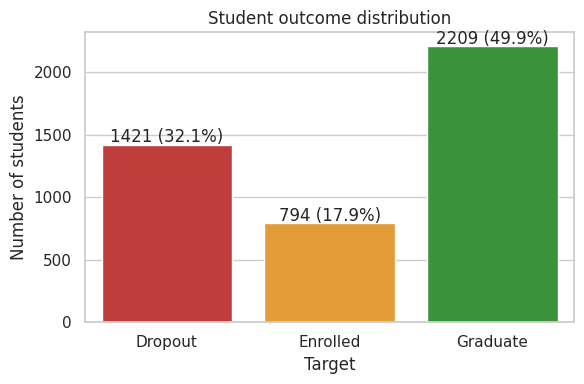

In [13]:
counts = df["Target"].value_counts().reindex(ORDER)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, palette=PAL, hue=counts.index, legend=False, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, f"{v} ({v / len(df) * 100:.1f}%)", ha="center")
ax.set_title("Student outcome distribution")
ax.set_ylabel("Number of students")
save("01_target_distribution")

px.pie(df, names="Target", color="Target", color_discrete_map=PAL,
       title="Outcome share (interactive)").show()

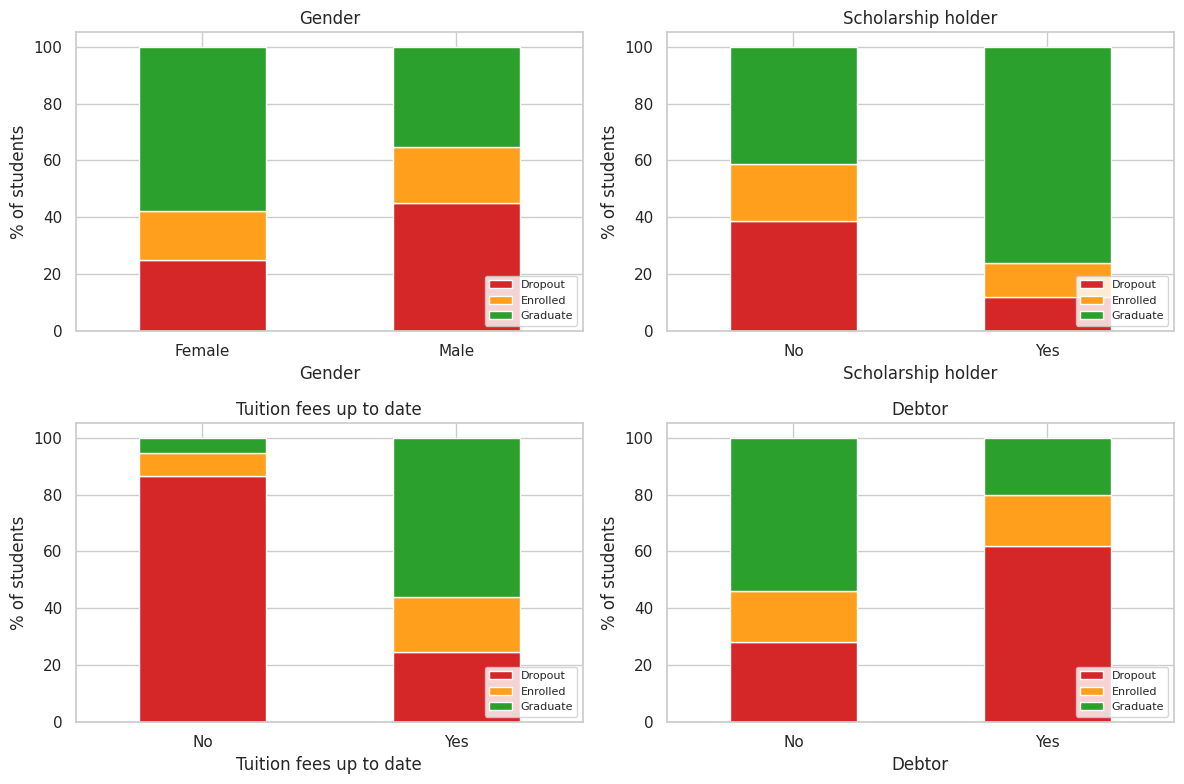

In [14]:
def pct_table(col, labels):
    t = pd.crosstab(df[col], df["Target"], normalize="index")[ORDER] * 100
    t.index = t.index.map(labels)
    return t

panels = [
    ("Gender", {0: "Female", 1: "Male"}, "Gender"),
    ("Scholarship holder", {0: "No", 1: "Yes"}, "Scholarship holder"),
    ("Tuition fees up to date", {0: "No", 1: "Yes"}, "Tuition fees up to date"),
    ("Debtor", {0: "No", 1: "Yes"}, "Debtor"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, labels, title) in zip(axes.ravel(), panels):
    pct_table(col, labels).plot(kind="bar", stacked=True,
                                color=[PAL[o] for o in ORDER], ax=ax, rot=0)
    ax.set_title(title)
    ax.set_ylabel("% of students")
    ax.legend(loc="lower right", fontsize=8)
save("02_dropout_by_category")

Unmapped courses: 0


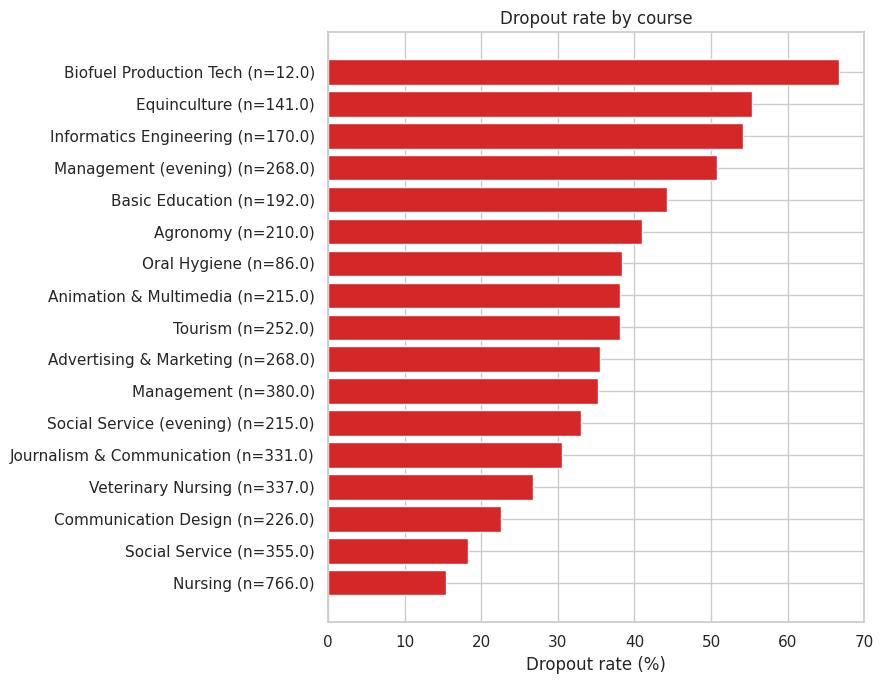

In [15]:
course_names = {
    33: "Biofuel Production Tech", 171: "Animation & Multimedia", 8014: "Social Service (evening)",
    9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing",
    9119: "Informatics Engineering", 9130: "Equinculture", 9147: "Management",
    9238: "Social Service", 9254: "Tourism", 9500: "Nursing", 9556: "Oral Hygiene",
    9670: "Advertising & Marketing", 9773: "Journalism & Communication",
    9853: "Basic Education", 9991: "Management (evening)",
}
df["Course name"] = df["Course"].map(course_names)
print("Unmapped courses:", df["Course name"].isnull().sum())

course = (df.groupby("Course name")
            .agg(students=("Target", "size"),
                 dropout_pct=("Target", lambda s: (s == "Dropout").mean() * 100))
            .sort_values("dropout_pct"))

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([f"{name} (n={r.students})" for name, r in course.iterrows()],
        course["dropout_pct"], color="#d62728")
ax.set_xlabel("Dropout rate (%)")
ax.set_title("Dropout rate by course")
save("03_dropout_by_course")

Target     Dropout  Enrolled  Graduate
Age group                             
<=19          21.0      17.0      62.1
20-24         28.6      22.6      48.9
25-29         57.6      16.9      25.5
30+           54.1      12.7      33.2


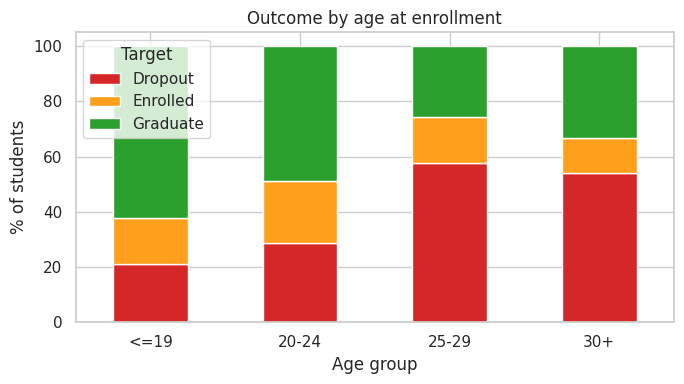

In [16]:
df["Age group"] = pd.cut(df["Age at enrollment"], [0, 19, 24, 29, 100],
                         labels=["<=19", "20-24", "25-29", "30+"])
age_tbl = (pd.crosstab(df["Age group"], df["Target"], normalize="index")[ORDER] * 100)
print(age_tbl.round(1))

age_tbl.plot(kind="bar", stacked=True, color=[PAL[o] for o in ORDER], figsize=(7, 4), rot=0)
plt.title("Outcome by age at enrollment"); plt.ylabel("% of students")
save("04_dropout_by_age")

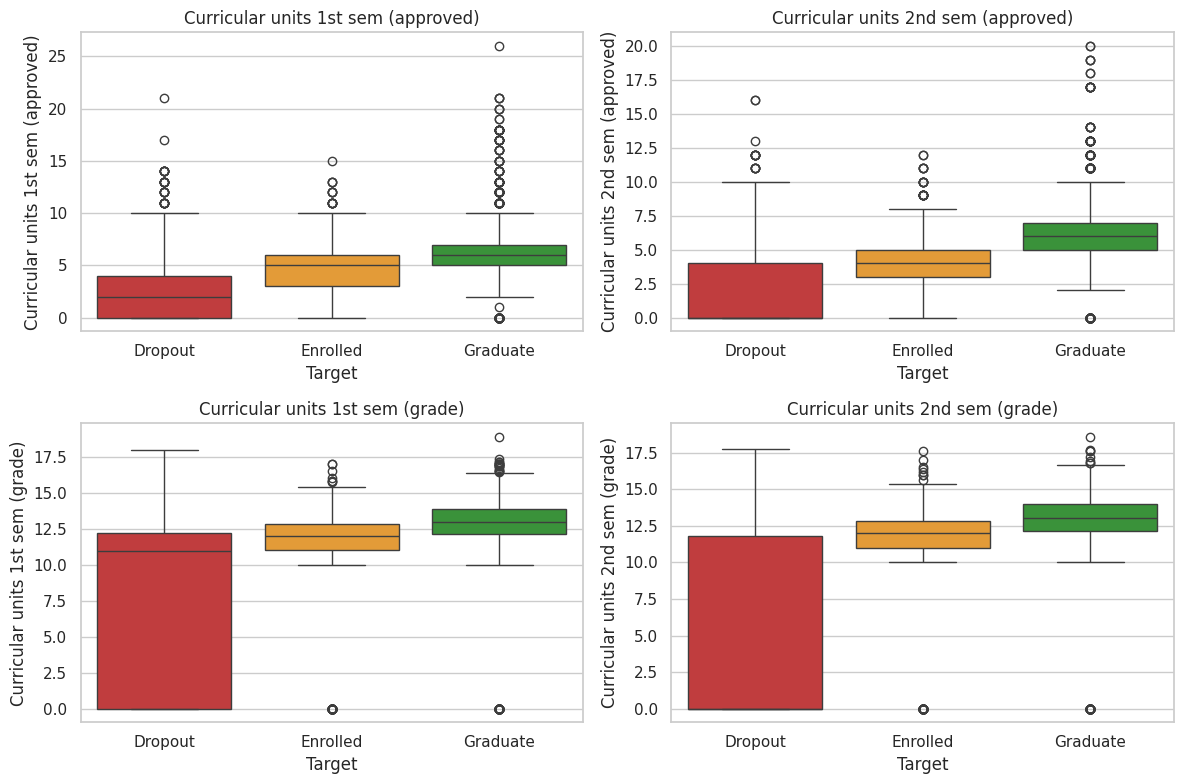

          Curricular units 1st sem (approved)  \
Target                                          
Dropout                                  2.55   
Enrolled                                 4.32   
Graduate                                 6.23   

          Curricular units 1st sem (grade)  
Target                                      
Dropout                               7.26  
Enrolled                             11.13  
Graduate                             12.64   

          Curricular units 2nd sem (approved)  \
Target                                          
Dropout                                  1.94   
Enrolled                                 4.06   
Graduate                                 6.18   

          Curricular units 2nd sem (grade)  
Target                                      
Dropout                               5.90  
Enrolled                             11.12  
Graduate                             12.70   



In [17]:
cols = ["Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)",
        "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x="Target", y=col, order=ORDER, palette=PAL,
                hue="Target", legend=False, ax=ax)
    ax.set_title(col)
save("05_performance_boxplots")

for s in ("1st", "2nd"):
    print(df.groupby("Target")[[f"Curricular units {s} sem (approved)",
                                f"Curricular units {s} sem (grade)"]].mean().round(2), "\n")

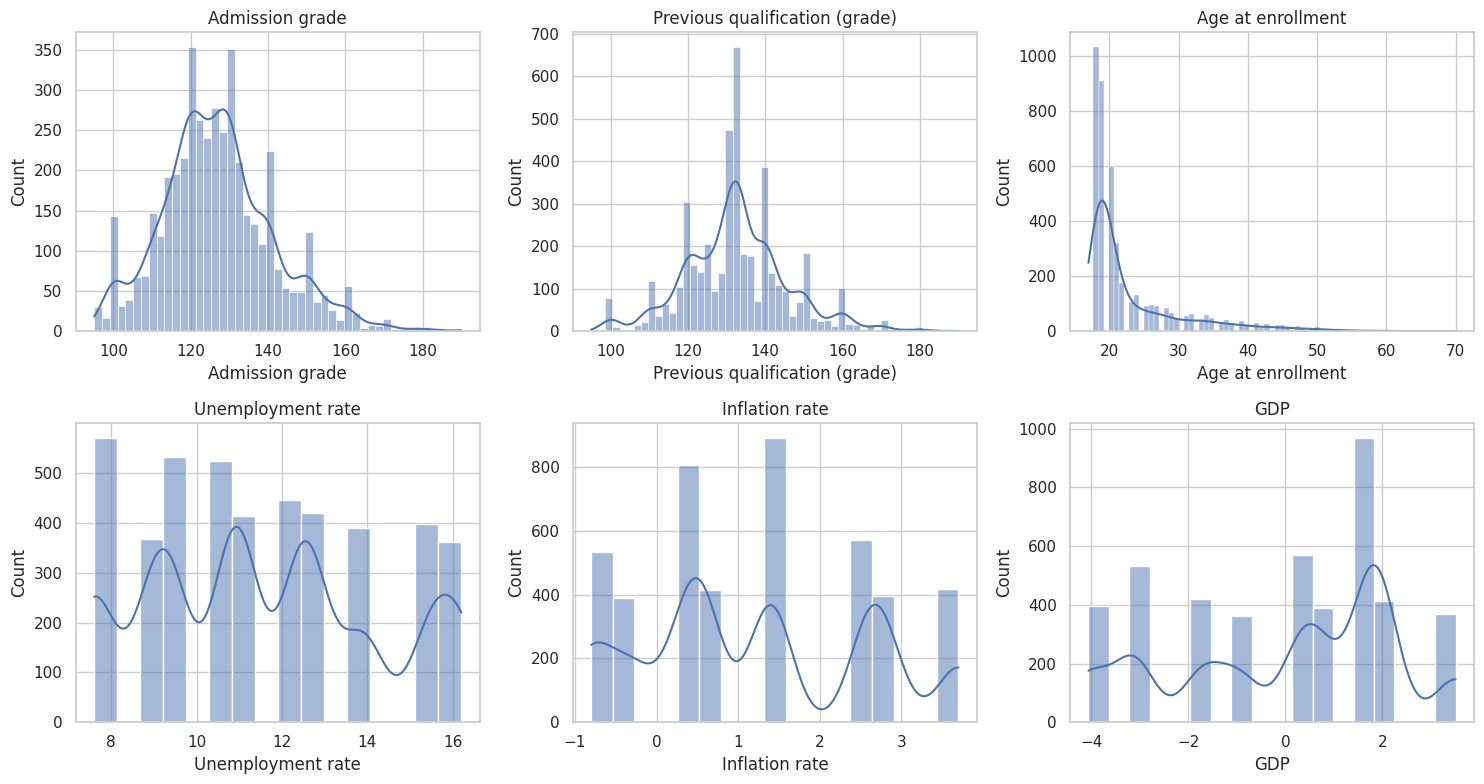

          Admission grade  Age at enrollment
Target                                      
Dropout            124.96              26.07
Enrolled           125.53              22.37
Graduate           128.79              21.78


In [18]:
num_cols = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
            "Unemployment rate", "Inflation rate", "GDP"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
save("06_numeric_distributions")

print(df.groupby("Target")[["Admission grade", "Age at enrollment"]].mean().round(2))

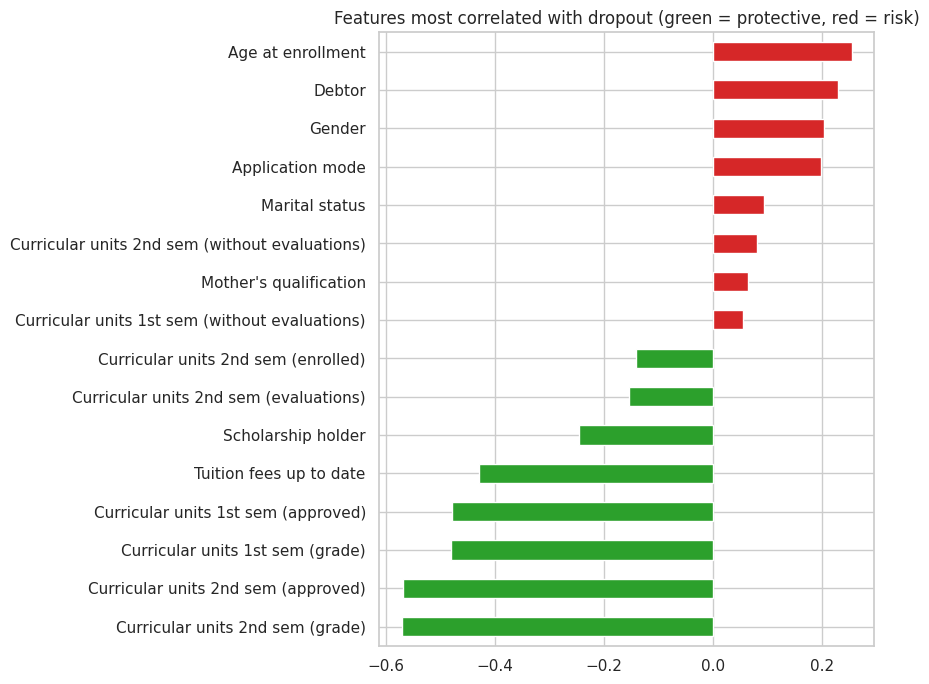

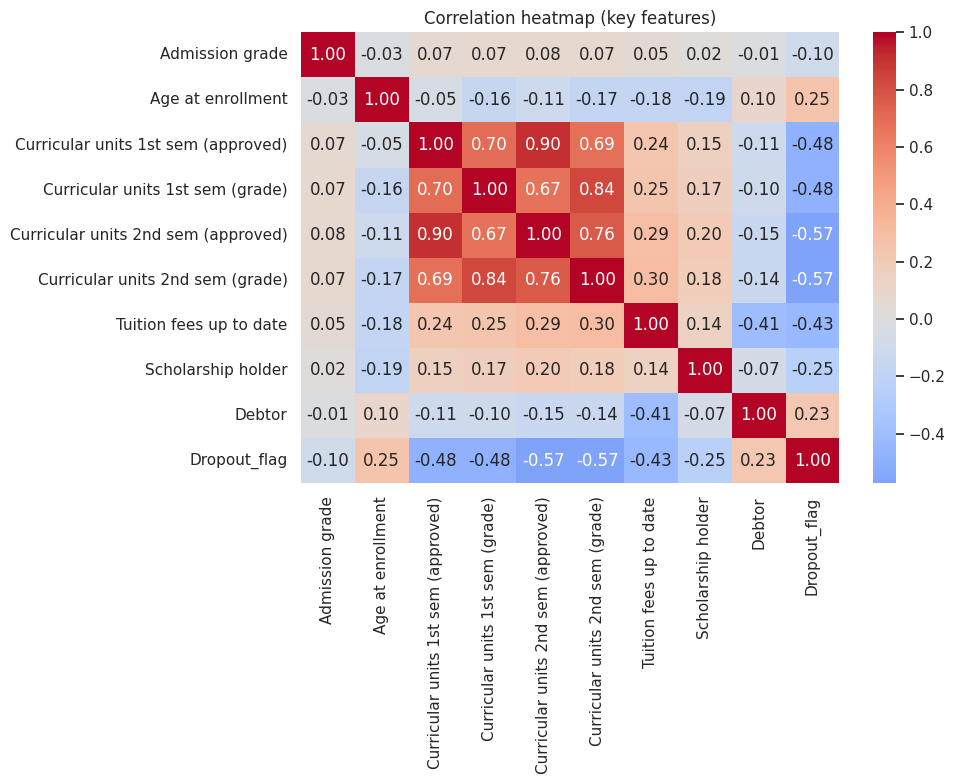

In [19]:
d = df.drop(columns=["Course name", "Age group"]).copy()
d["Dropout_flag"] = (d["Target"] == "Dropout").astype(int)
corr = d.drop(columns="Target").corr()["Dropout_flag"].drop("Dropout_flag").sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])

fig, ax = plt.subplots(figsize=(9, 7))
top.plot(kind="barh", color=["#2ca02c" if v < 0 else "#d62728" for v in top], ax=ax)
ax.set_title("Features most correlated with dropout (green = protective, red = risk)")
save("07_correlation_with_dropout")

key = ["Admission grade", "Age at enrollment",
       "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
       "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)",
       "Tuition fees up to date", "Scholarship holder", "Debtor", "Dropout_flag"]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(d[key].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation heatmap (key features)")
save("08_correlation_heatmap")

In [20]:
sample = df.sample(1500, random_state=42)
fig = px.scatter(sample, x="Curricular units 1st sem (grade)", y="Curricular units 2nd sem (grade)",
                 color="Target", color_discrete_map=PAL, opacity=0.6,
                 hover_data=["Age at enrollment", "Tuition fees up to date"],
                 title="1st vs 2nd semester grade (1500 random students)")
fig.show()

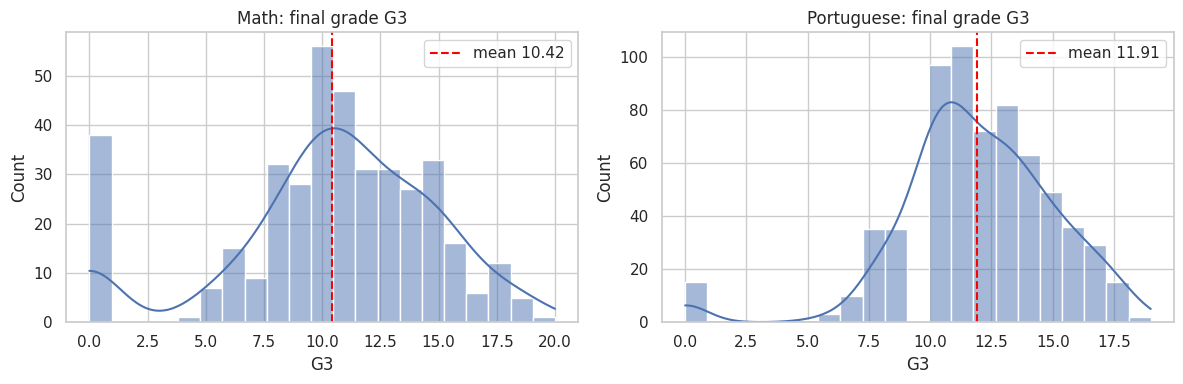

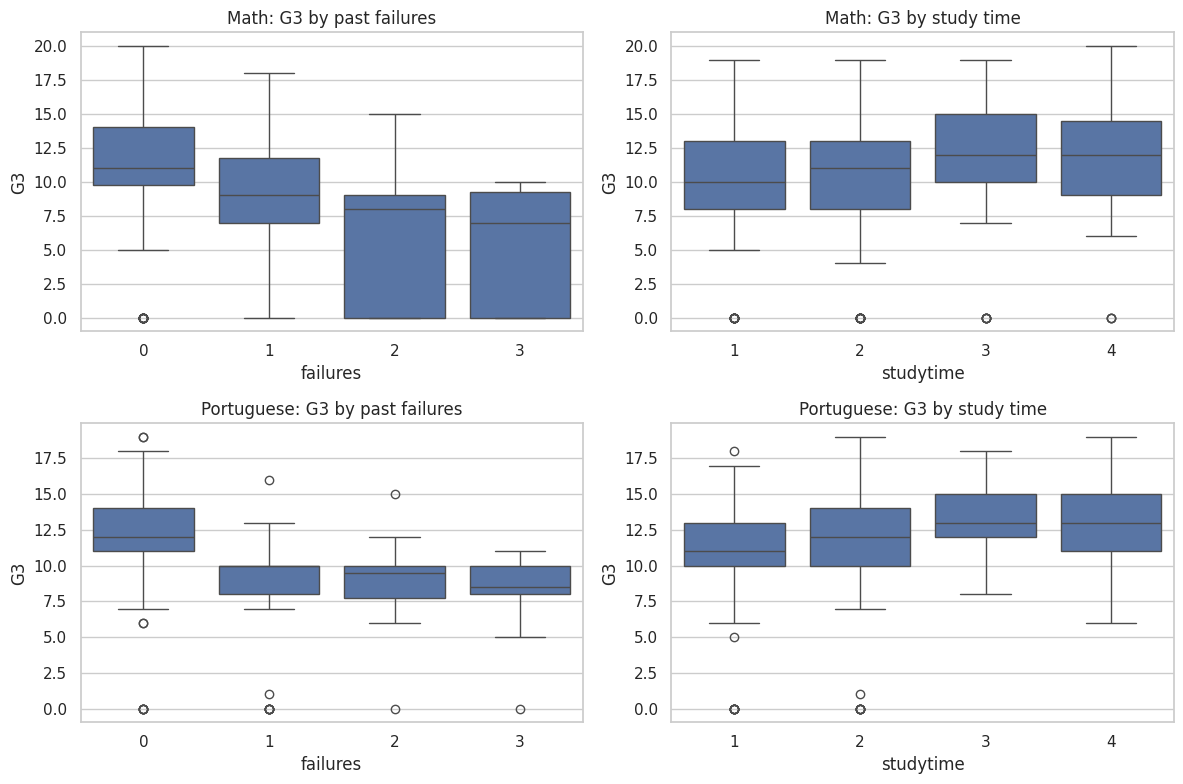

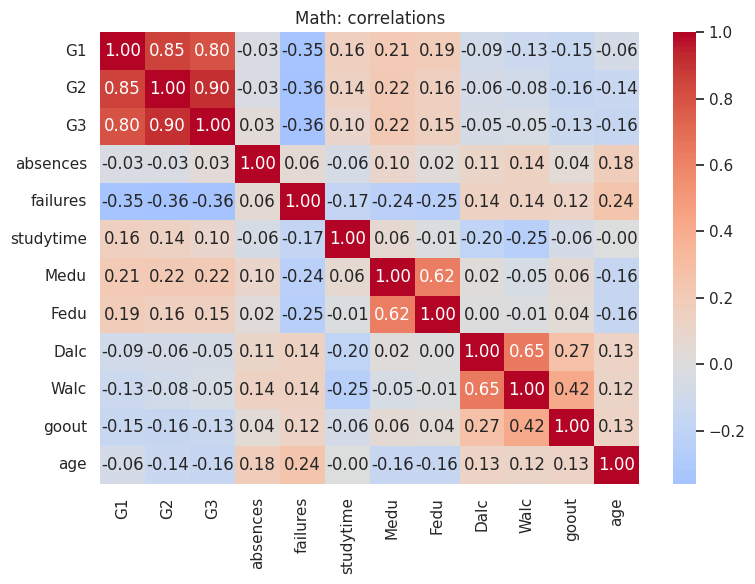

Math | mean G3: 10.42 | share below 10: 32.9%
  G3 by failures: {0: 11.25, 1: 8.12, 2: 6.24, 3: 5.69}
  G3 by wants higher education: {'no': 6.8, 'yes': 10.61}
  correlation with G3: {'G1': 0.8, 'G2': 0.9, 'failures': -0.36, 'studytime': 0.1, 'Medu': 0.22, 'absences': 0.03}
Portuguese | mean G3: 11.91 | share below 10: 15.4%
  G3 by failures: {0: 12.51, 1: 8.64, 2: 8.81, 3: 8.07}
  G3 by wants higher education: {'no': 8.8, 'yes': 12.28}
  correlation with G3: {'G1': 0.83, 'G2': 0.92, 'failures': -0.39, 'studytime': 0.25, 'Medu': 0.24, 'absences': -0.09}


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, s) in zip(axes, [("Math", math), ("Portuguese", por)]):
    sns.histplot(s["G3"], bins=21, kde=True, ax=ax)
    ax.axvline(s["G3"].mean(), color="red", linestyle="--", label=f"mean {s['G3'].mean():.2f}")
    ax.set_title(f"{name}: final grade G3"); ax.legend()
save("09_g3_distribution")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r, (name, s) in enumerate([("Math", math), ("Portuguese", por)]):
    sns.boxplot(data=s, x="failures", y="G3", ax=axes[r, 0]); axes[r, 0].set_title(f"{name}: G3 by past failures")
    sns.boxplot(data=s, x="studytime", y="G3", ax=axes[r, 1]); axes[r, 1].set_title(f"{name}: G3 by study time")
save("10_performance_factors")

cc = ["G1", "G2", "G3", "absences", "failures", "studytime", "Medu", "Fedu", "Dalc", "Walc", "goout", "age"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(math[cc].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Math: correlations")
save("11_math_correlation")

for name, s in [("Math", math), ("Portuguese", por)]:
    print(name, "| mean G3:", round(s["G3"].mean(), 2), "| share below 10:", f"{(s['G3'] < 10).mean():.1%}")
    print("  G3 by failures:", s.groupby("failures")["G3"].mean().round(2).to_dict())
    print("  G3 by wants higher education:", s.groupby("higher")["G3"].mean().round(2).to_dict())
    print("  correlation with G3:", s[["G1", "G2", "failures", "studytime", "Medu", "absences"]].corrwith(s["G3"]).round(2).to_dict())

In [22]:
import shutil
shutil.make_archive("/content/eda_figures", "zip", FIG)
from google.colab import files
files.download("/content/eda_figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>